In [1]:
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

C:\Users\johnl\AppData\Local\Temp\ipykernel_18256\3777615979.py:1: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, HTML


In [2]:
# # Installing the SHAP library
# !pip install -q shap

# Lecture 7 - XAI using SHAP

## Introduction

Explainable Artificial Intelligence (XAI) has emerged as a pivotal subfield within machine learning and artificial intelligence, addressing the opacity of complex models. The essence of XAI is to make the decision-making process of algorithms transparent, interpretable, and justifiable. This is particularly crucial in sensitive domains such as healthcare, finance, and criminal justice, where the stakes are high and the cost of errors can be significant.

The need for XAI arises from the increasing complexity of machine learning models, especially deep learning architectures, which are often considered 'black boxes.' While these models may achieve high predictive accuracy, their decision-making process is not easily understandable by humans. XAI aims to bridge this gap by providing tools and methodologies to 'open the black box' and make the algorithm's decisions transparent and understandable.

In this tutorial, we will focus on SHAP (SHapley Additive exPlanations), a game-theoretic approach to explain the output of any machine learning model. SHAP connects optimal credit allocation with local explanations through the classic Shapley values from cooperative game theory and their related extensions.

### Objectives

- To demystify the concept of XAI and its significance in contemporary machine learning.
- To provide a nuanced understanding of SHAP and its applications.
- To equip you with the skills to apply SHAP to machine learning models and interpret its various plots.


As we navigate through this tutorial, we will engage in discourse and applying critical thinking to address current challenges and needs in XAI.

## What is Explainable Artificial Intelligence (XAI)?

Explainable Artificial Intelligence (XAI) is an emerging subfield within machine learning that aims to make the decision-making process of algorithms transparent, understandable, and interpretable. The goal is to bridge the gap between the complexity of machine learning models and the necessity for human interpretability.

### Why is XAI Important?

- **Accountability**: Ensures that machine learning models are accountable for their decisions.
- **Fairness**: Helps in identifying and mitigating biases in the model's decisions.
- **Trust**: Builds trust between humans and machines by making the decision-making process transparent.
- **Regulatory Compliance**: Meets the requirements of regulations like GDPR, which mandates the right to explanation for automated decisions.

### The Philosophical Underpinnings of XAI

The quest for explainability in AI can be traced back to the philosophical discussions on epistemology, the study of knowledge. How do we know what we know? In the context of AI, this translates to understanding how a model 'knows' or 'decides' a particular outcome. The epistemological journey in XAI involves dissecting the model's decision-making process, thereby making the unknown known.

### The Technical Challenges in XAI

Achieving explainability is easier said than done. Complex models like neural networks involve millions of parameters, and their decision boundaries can be highly non-linear and multi-dimensional. Simplifying this complexity without losing the essence of the model's decision-making capability is a significant challenge.

### The Ethical Imperatives

Beyond the technical and philosophical aspects, XAI also has ethical imperatives. In healthcare, for example, a misclassification by an AI model could be a matter of life and death. Therefore, it is ethically imperative to understand how the model is making its decisions to ensure its reliability and safety.


In the subsequent sections, we will focus on SHAP, a powerful tool for achieving XAI.

## What is SHAP (SHapley Additive exPlanations)?

SHAP, or SHapley Additive exPlanations, is a unified framework for interpreting model predictions. It is based on Shapley values, a concept from cooperative game theory. However, let's set aside the mathematical intricacies for a moment and focus on its practical utility.

Imagine you are a doctor trying to predict the likelihood of a patient readmission to the hospital. You have a complex machine learning model that uses various features like age, medical history, and lab results. While the model is highly accurate, you're not sure why it predicts a high likelihood of readmission for a particular patient. This is where SHAP comes in.

SHAP would break down the model's prediction for that specific patient into contributions from each feature. For instance, it might reveal that the patient's age contributes positively to the prediction, while a certain medication they are taking reduces the likelihood of readmission. This granular insight allows you to understand the 'why' behind the model's prediction, enabling more informed decision-making.


### Advantages of SHAP

- **Consistency**: If a feature's value changes such that it contributes more to the prediction, its Shapley value should not decrease.
- **Local Accuracy**: Each prediction is explained by the sum of the Shapley values and the base value of the model.
- **Global Interpretability**: Aggregated SHAP values can provide a global view of feature importance.

In the following sections, we will apply SHAP to a machine learning model and interpret its various plots.

We will be using the load_bosting real estate dataset: http://lib.stat.cmu.edu/datasets/boston

The dataset is described by the authors as follows:




In [3]:
# Importing necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
# from sklearn.datasets import load_boston
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]
columns = [
    'CRIM',
    'ZN',
    'INDUS',
    'CHAS',
    'NOX',
    'RM',
    'AGE',
    'DIS',
    'RAD',
    'TAX',
    'PTRATIO',
    'B',
    'LSTAT',
    'MEDV',
]

In [4]:
boston = pd.read_csv(
    filepath_or_buffer="http://lib.stat.cmu.edu/datasets/boston",
    delim_whitespace=True,
    skiprows=21,
    header=None,
)

columns = [
    'CRIM',
    'ZN',
    'INDUS',
    'CHAS',
    'NOX',
    'RM',
    'AGE',
    'DIS',
    'RAD',
    'TAX',
    'PTRATIO',
    'B',
    'LSTAT',
    'MEDV',
]

#Flatten all the values into a single long list and remove the nulls
values_w_nulls = boston.values.flatten()
all_values = values_w_nulls[~np.isnan(values_w_nulls)]

#Reshape the values to have 14 columns and make a new df out of them
boston = pd.DataFrame(
    data = all_values.reshape(-1, len(columns)),
    columns = columns,
)

boston

C:\Users\johnl\AppData\Local\Temp\ipykernel_14916\2359151895.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  boston = pd.read_csv(


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48,22.0


In [5]:

# Load the Boston Housing dataset
# boston = load_boston()
X = boston.drop(columns = ['MEDV'])
y = pd.Series(boston['MEDV'])

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a RandomForestRegressor model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')

medea = mean_absolute_error(y_test, y_pred)
print(f'Median Absolute Error: {medea}')

Mean Squared Error: 7.901513892156864
Median Absolute Error: 2.0395392156862746


In [6]:
X

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48


In [7]:
y

0      24.0
1      21.6
2      34.7
3      33.4
4      36.2
       ... 
501    22.4
502    20.6
503    23.9
504    22.0
505    11.9
Name: MEDV, Length: 506, dtype: float64

array([[<Axes: title={'center': 'CRIM'}>, <Axes: title={'center': 'ZN'}>,
        <Axes: title={'center': 'INDUS'}>,
        <Axes: title={'center': 'CHAS'}>],
       [<Axes: title={'center': 'NOX'}>, <Axes: title={'center': 'RM'}>,
        <Axes: title={'center': 'AGE'}>, <Axes: title={'center': 'DIS'}>],
       [<Axes: title={'center': 'RAD'}>, <Axes: title={'center': 'TAX'}>,
        <Axes: title={'center': 'PTRATIO'}>,
        <Axes: title={'center': 'B'}>],
       [<Axes: title={'center': 'LSTAT'}>, <Axes: >, <Axes: >, <Axes: >]],
      dtype=object)

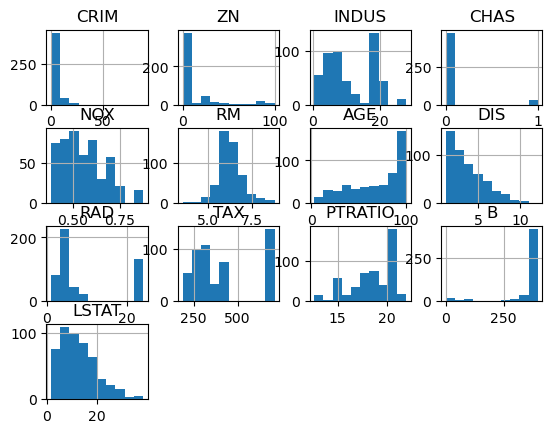

In [8]:
X.hist()

<Axes: >

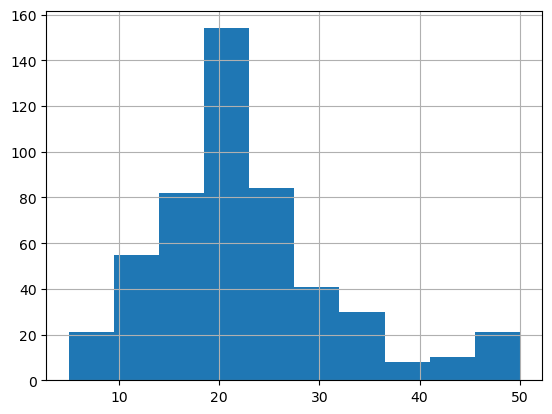

In [9]:
y.hist()

## Model Training and Evaluation

We have trained a RandomForestRegressor model on the Boston Housing dataset and evaluated its performance using the Mean Squared Error (MSE) metric. The MSE for our model is approximately 7.90, which serves as a quantitative measure of the model's accuracy.

Next, we will use SHAP to interpret this model. We will generate various types of SHAP plots to understand how each feature contributes to individual predictions as well as to the model's overall decision-making process.

In [10]:
X_test.iloc[0,:]

CRIM         0.09178
ZN           0.00000
INDUS        4.05000
CHAS         0.00000
NOX          0.51000
RM           6.41600
AGE         84.10000
DIS          2.64630
RAD          5.00000
TAX        296.00000
PTRATIO     16.60000
B          395.50000
LSTAT        9.04000
Name: 173, dtype: float64

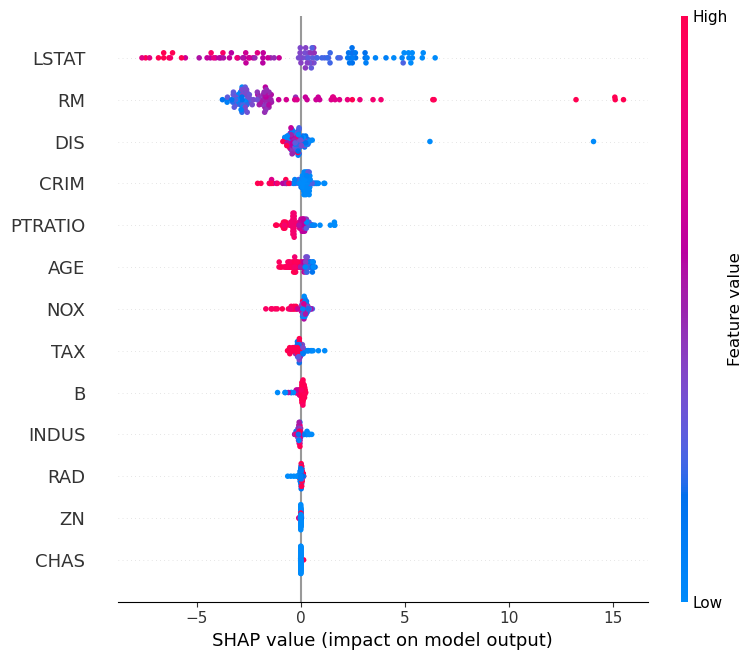

In [6]:
# Initialize the SHAP explainer
explainer = shap.Explainer(model, X_train)

# Compute SHAP values for a single prediction
shap_values_single = explainer(X_test.iloc[0, :])

# Compute SHAP values for the test set
shap_values = explainer(X_test)

# Summary plot
shap.summary_plot(shap_values, X_test)

## Summary Plot

The summary plot provides a holistic view of feature importance and how each feature impacts the model's predictions. In this plot, each point represents a Shapley value for a feature and an instance. The position on the y-axis indicates the feature, and the position on the x-axis indicates the Shapley value. The color represents the value of the feature from low to high.

### Observations

- **LSTAT (Lower Status of the Population)**: This feature has the most significant impact on the model's predictions. Higher values of LSTAT generally lead to lower house prices, as indicated by the negative Shapley values.
- **RM (Average Number of Rooms)**: This feature also has a substantial impact but in the opposite direction. More rooms usually result in higher house prices.
- **DIS (Distance to Employment Centers)**: This feature has a moderate impact, and its effect is more nuanced, as indicated by the spread of Shapley values.

The summary plot serves as a powerful tool for understanding the global behavior of the model. Next, we will look at waterfall plots for individual predictions.

Recommendations:

    Model Development Phase: During the model development phase, it's beneficial to generate SHAP plots on the training data to understand how the model is making decisions.
    Model Validation Phase: Once the model is trained, generating SHAP plots on the test data can provide insights into how well the model is likely to generalize.

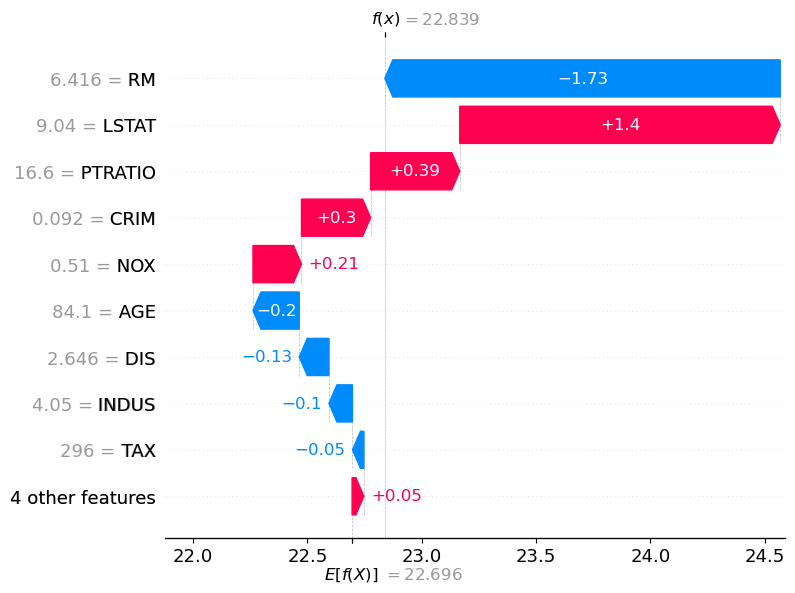

In [12]:
# Waterfall plot for the first prediction in the test set
shap.plots.waterfall(shap_values[0])

## Waterfall Plot

The waterfall plot provides a detailed explanation of a single prediction by breaking down the prediction into its constituent feature contributions. The plot starts with the model's base value and adds the Shapley values for each feature to arrive at the final prediction.

### Observations

- **Base Value**: The base value is the average prediction of the model for the training set. It serves as the starting point for the waterfall plot.
- **RM**: This feature and its value have a negative impact, decreasing the forecast by 1.46
- **LSTAT**: This feature and value has a significant positive impact on the prediction, increasing the forecast by approx 1.37
- **CRIM**: The low crime value pushes the forecast up.

The waterfall plot offers a granular view of how each feature contributes to a specific prediction, making it an invaluable tool for local interpretability. Next, we will explore dependence plots.

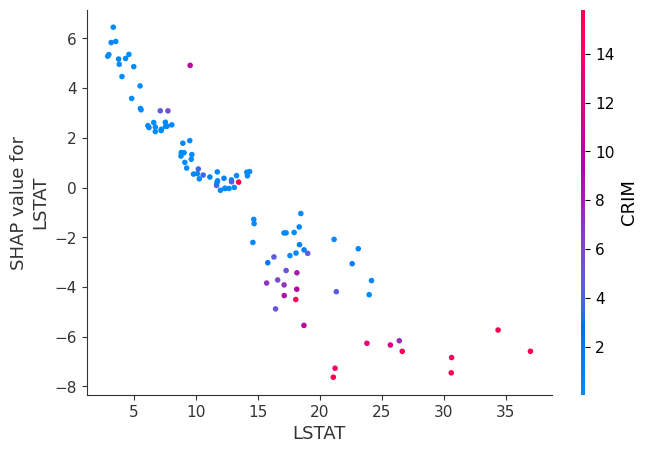

In [13]:
# Dependence plot for the feature 'LSTAT'
shap.dependence_plot('LSTAT', shap_values.values, X_test)

## Dependence Plot

The dependence plot illustrates how the Shapley values for a specific feature vary across the dataset. It helps in understanding the relationship between a feature and the model's output.

### Observations

- **Negative Correlation**: The plot shows a negative correlation between the feature 'LSTAT' and the Shapley values, confirming that higher values of 'LSTAT' generally lead to lower predictions.
- **Non-linearity**: The plot reveals a non-linear relationship, indicating that the effect of 'LSTAT' on the prediction is not constant across its range.
- **Interaction Effects**: The color gradient represents the values of another feature, allowing us to observe potential interaction effects between features.

The dependence plot is particularly useful for understanding complex relationships and interactions between features. W

# Exercises

The following exercises are designed to reinforce your understanding of SHAP and its applications. These exercises will involve generating and interpreting various types of SHAP plots.


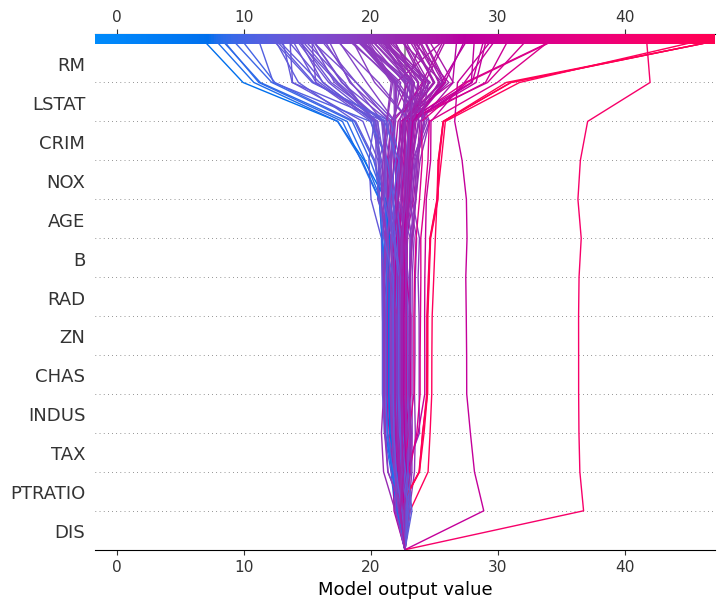

In [7]:
expected_value = explainer.expected_value

shap.decision_plot(expected_value, explainer.shap_values(X_test), X_test, feature_order='hclust') # hclust Groups similar prediction paths

### Exercise: Create a summary plot on the above model for the training data and interpret. Plot the same graph using test data and compare.

In [8]:
shap_values_ebm[sample_ind : sample_ind + 1, :]

NameError: name 'shap_values_ebm' is not defined

In [9]:
# X100 = shap.utils.sample(X, 100) 

# explainer_ebm = shap.Explainer(model.predict, X100)
# shap_values_ebm = explainer_ebm(X)
sample_ind = 5
shap.partial_dependence_plot(
    "CRIM",
    model.predict,
    X100,
    model_expected_value=True,
    feature_expected_value=True,
    show=False,
    ice=False,
    shap_values=shap_values_ebm[sample_ind : sample_ind + 1, :],
)

NameError: name 'X100' is not defined

### Exercise: Train a Gradient Boosting Regressor on the same Boston Housing dataset and generate a SHAP summary plot. Plot the summary graphs from both models. Compare the feature importances with those of the RandomForestRegressor on the test dataset.

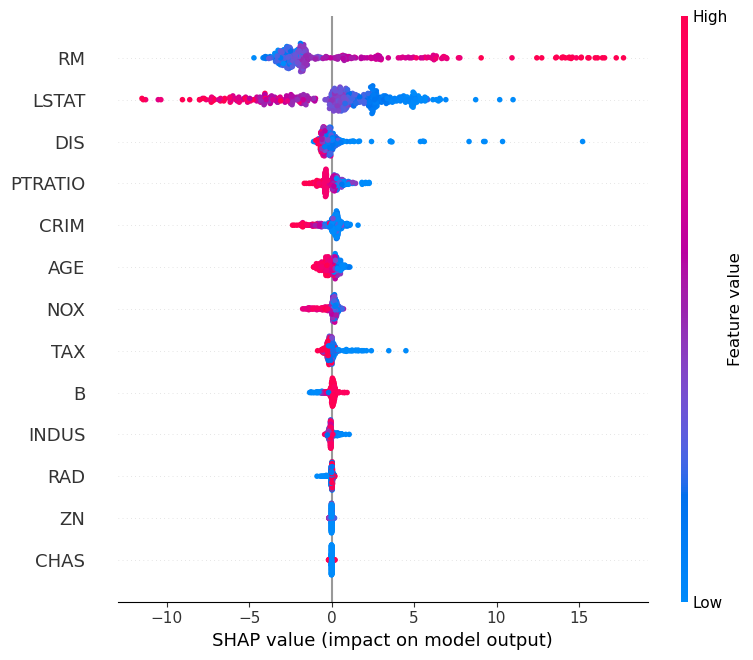

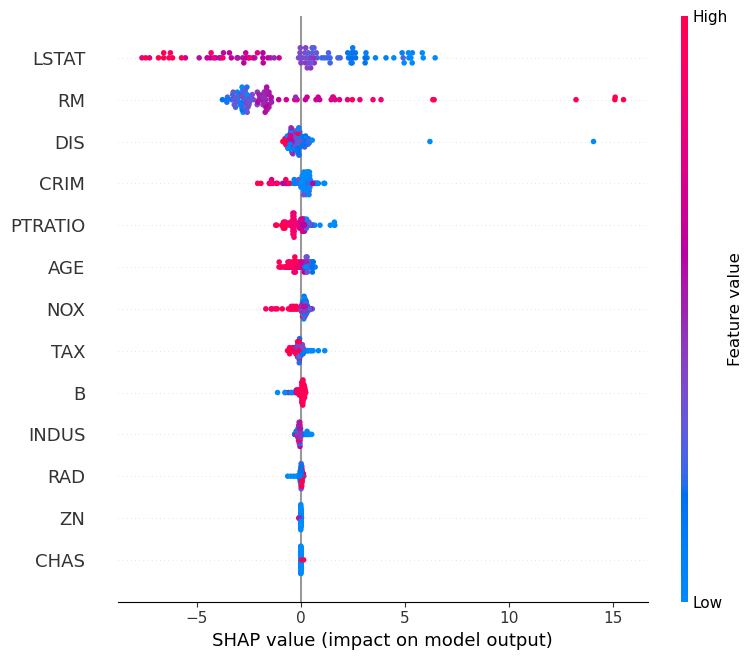

In [10]:
explainer = shap.Explainer(model, X_train)

shap_values_train = explainer(X_train)

shap.summary_plot(shap_values_train, X_train)
shap.summary_plot(shap_values, X_test)

1.9122427713612915
6.208861361528038


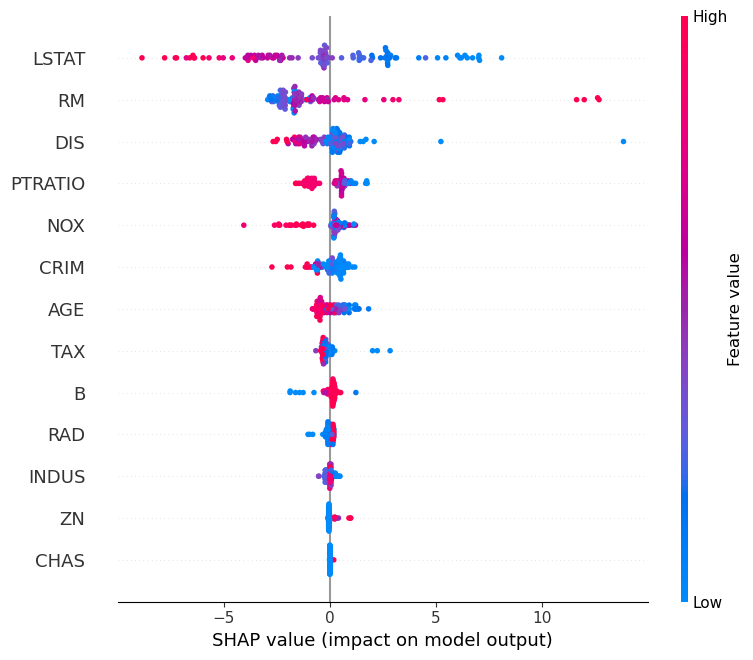

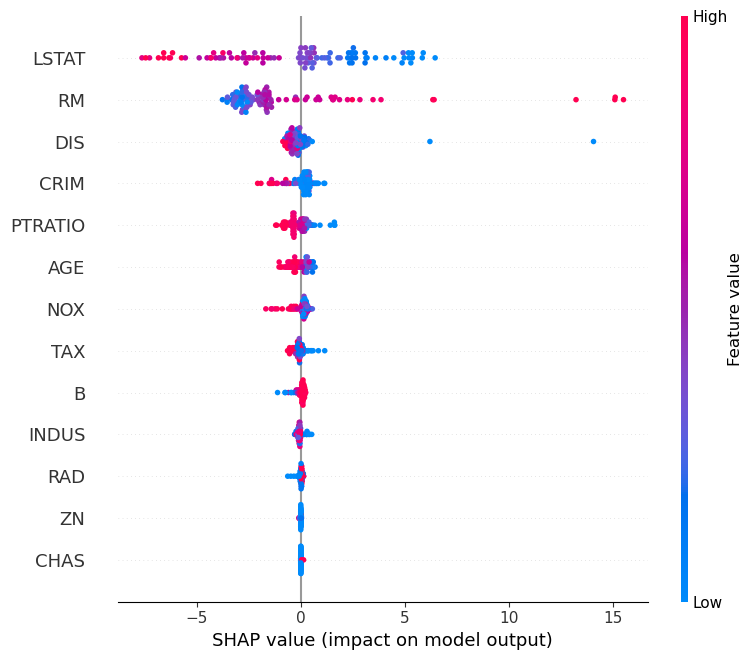

In [11]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(n_estimators = 100, random_state = 42)
gb_model.fit(X_train, y_train)
y_pred = gb_model.predict(X_test)
medae = mean_absolute_error(y_test, y_pred)
print(mean_absolute_error(y_test, y_pred))
print(mean_squared_error(y_test, y_pred))

gb_explainer = shap.Explainer(gb_model, X_train)
gb_shap_values = gb_explainer(X_test)

shap.summary_plot(gb_shap_values, X_test, title = 'Gradient Boosting Model')
shap.summary_plot(shap_values, X_test, title = 'Random Forest Boosting Model')



### Exercise: Generate a waterfall plot for the 10th instance in the test set using the RandomForestRegressor model. Interpret the feature contributions.

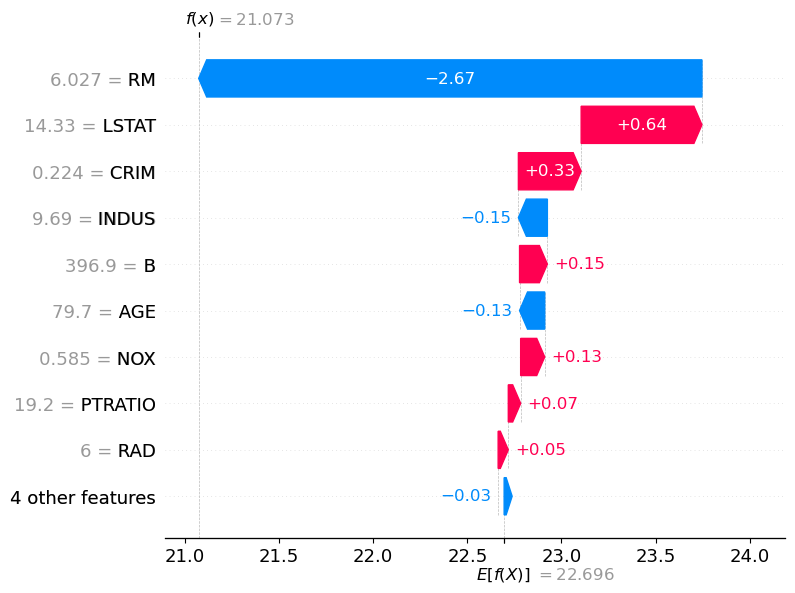

In [17]:
shap.plots.waterfall(shap_values[9])

### Exercise: Repeat the above on for the Gradient Boosting:

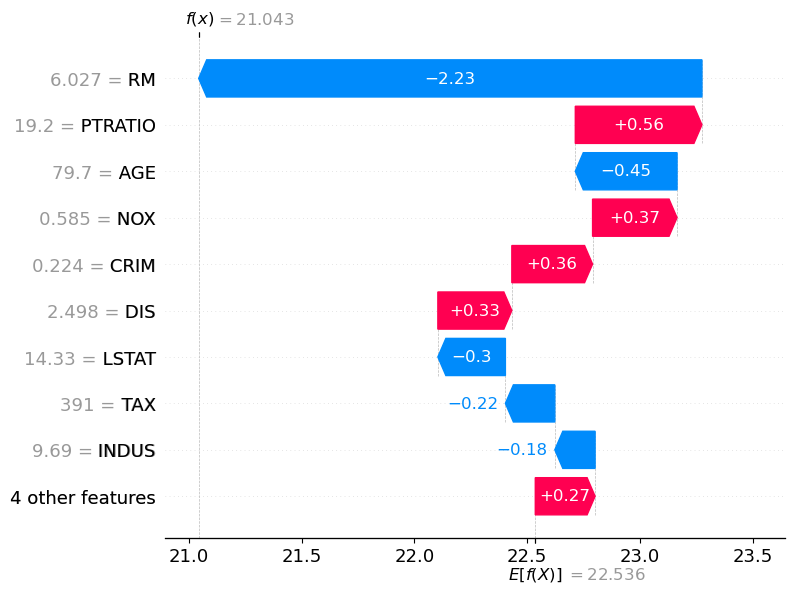

In [18]:
shap.plots.waterfall(gb_shap_values[9])

### Exercise : Generate a dependence plot for the feature 'RM' (Average Number of Rooms) using the RandomForestRegressor model. What observations can you make?


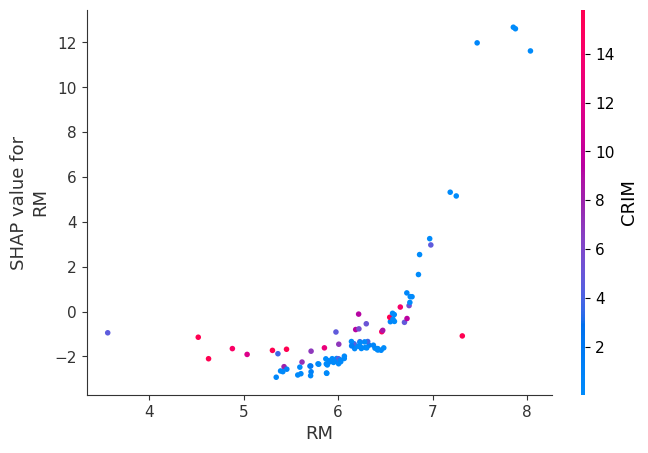

In [13]:
X_display, y_display = shap.datasets.nhanesi(display=True)
shap.dependence_plot('RM', gb_shap_values.values, X_test, display_features=X_display)

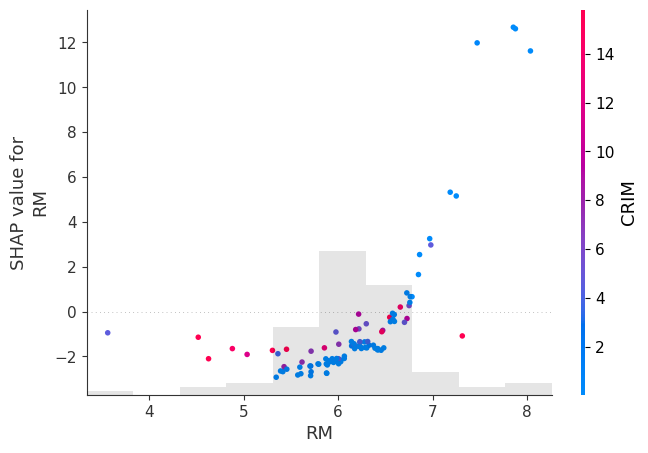

In [12]:
shap.plots.scatter(gb_shap_values[:, "RM"], color=shap_values)


### Exercise : Now modify the dependence plot above and display the dependence between the 'RM' and 'AGE' features.


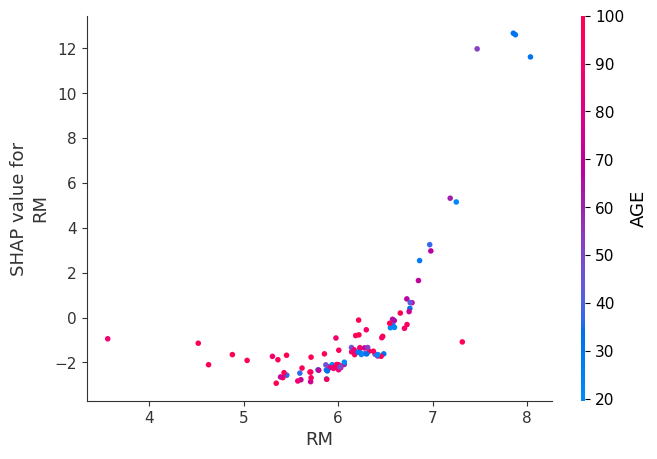

In [14]:
shap.dependence_plot('RM', gb_shap_values.values, X_test,color=shap_values, interaction_index = 'AGE')


In [ ]:
# shap_interaction_values = shap.TreeExplainer(model).shap_interaction_values(X.iloc[:,1:3])
# 

In [1]:
# shap.dependence_plot(
#     ("ZN", "INDUX"),
#     shap_interaction_values,
#     X.iloc[:,1:3],
#     display_features=X_display.iloc[:,1:3],
# )

### Exercise: Improve the Random Forest model by selecting a subset of relevant features and then re-train the model and depict the new summary plot on the training samples.


In [23]:
X= X[['LSTAT', 'RM', 'DIS', 'CRIM']]
# Load the Boston Housing dataset
# boston = load_boston()
# X = boston.drop(columns = ['MEDV'])
y = pd.Series(boston['MEDV'])

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a RandomForestRegressor model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')

medea = mean_absolute_error(y_test, y_pred)
print(f'Median Absolute Error: {medea}')

Mean Squared Error: 11.263735509803928
Median Absolute Error: 2.2718039215686288


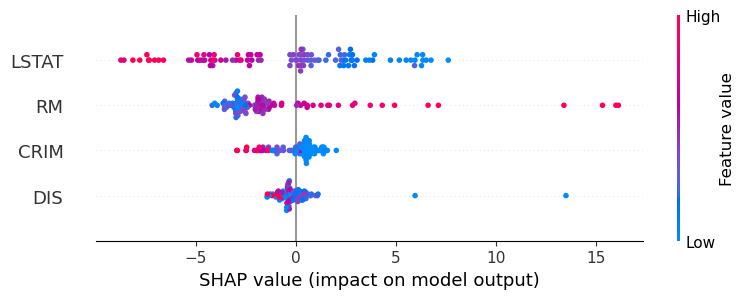

In [24]:
# Initialize the SHAP explainer
explainer = shap.Explainer(model, X_train)

# Compute SHAP values for a single prediction
shap_values_single = explainer(X_test.iloc[0, :])

# Compute SHAP values for the test set
shap_values = explainer(X_test)

# Summary plot
shap.summary_plot(shap_values, X_test)

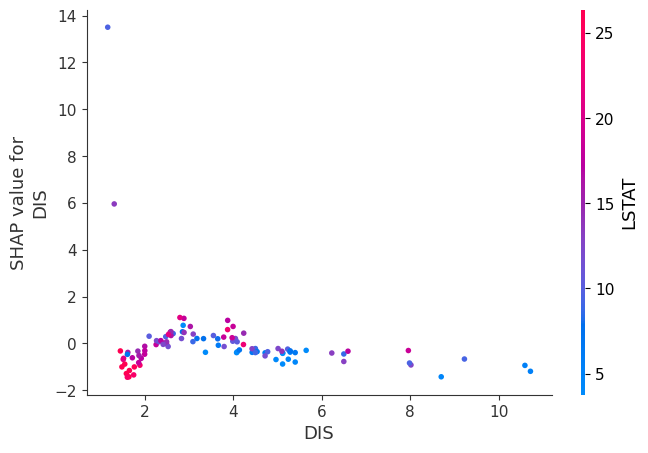

In [26]:
shap.dependence_plot('DIS', shap_values.values, X_test,color=shap_values)


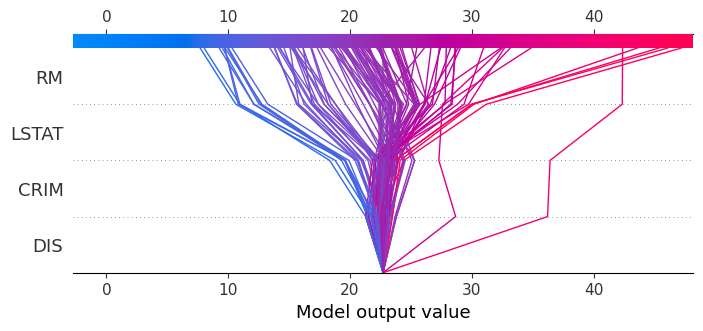

In [28]:
expected_value = explainer.expected_value

shap.decision_plot(expected_value, explainer.shap_values(X_test), X_test, feature_order='hclust') # hclust Groups similar prediction paths

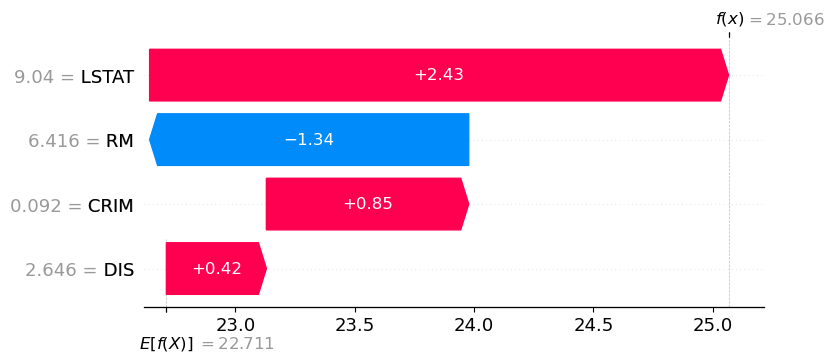

In [39]:
shap.plots.waterfall(shap_values[0])

### Exercise: Different Dataset

Import the diabetes dataset and perform the same analyses as above

### Exercise: Explain How SHAP Values Can Be Used for Feature Selection


### Exercise: Discuss the Limitations and Advantages of Using SHAP in XAI

